# 1D scenarios

This is a notebook that explores MSSR model in 1D space, so that it is easy to understand concepts :-) 

In [32]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 7
NOISE_STD = 0.05

# Because our shifts would be in HR space, and we downsample by 2 – we need to have max shift of 2
MIN_SHIFT = 0.01
MAX_SHIFT = 1.99
 
def draw_1d(v, title=""):
    plt.figure(figsize=(len(v), 2))
    plt.bar(np.arange(len(v)), v, color="dimgray")
    plt.axhline(1, color="red", lw=0.8, ls="--")
    plt.axhline(0, color="black", lw=0.8)
    plt.xticks(np.arange(len(v)))
    if title:
        plt.title(title)
    plt.show()
    
rng = np.random.default_rng(SEED)

In [33]:
HR_1D = np.array([0, 0, 1, 1, 0, 0]) 
# This is our original HR image that we are trying to reconstruct

# Naive 1D MSSR (w/o noise or blur)

Model is: y_k = D * M_k * x

- x - original high res image
- D - downsamplint – we will downsample by getting average of 2 adjacent pixels)
- M_k motion matrix – we know this, since for this example we select shifts ourselves 

In [34]:
def generate_2x_avg_D(n):
    D = np.zeros((n // 2, n))
    for i in range(n // 2):
        D[i, 2*i] = D[i, 2*i + 1] = 0.5
    return D

def generate_M(n, shift):
    s = int(np.floor(shift))
    eps = shift - s
    M = np.zeros((n, n))
    for i in range(n):
        if 0 <= i + s < n:     M[i, i + s] = 1 - eps
        if 0 <= i + s + 1 < n: M[i, i + s + 1] += eps
    return M

def generate_lr_image(hr, D, shift):
    return D @ generate_M(len(hr), shift) @ hr # becuse y_k = D * M_k * x

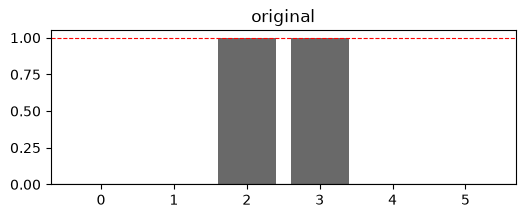

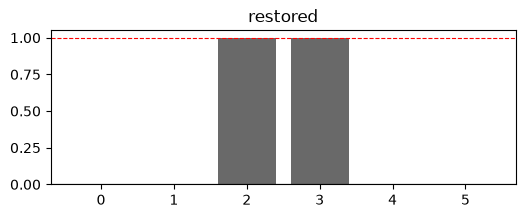

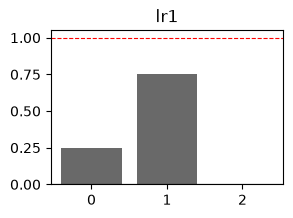

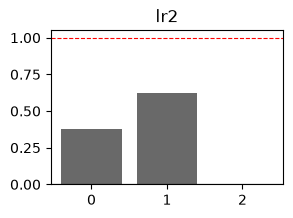

In [35]:
def naive(shift_1, shift_2):
    D = generate_2x_avg_D(len(HR_1D))
    M1 = generate_M(len(HR_1D), shift_1)
    M2 = generate_M(len(HR_1D), shift_2)

    lr1 = generate_lr_image(HR_1D, D, shift_1)
    lr2 = generate_lr_image(HR_1D, D, shift_2)

    # Now that we have: D, M, and our LR images, we can solve system of equations to find original HR image

    A = np.vstack([D @ M1, D @ M2]) # as in Ax = y
    x = np.linalg.solve(A, np.concatenate([lr1, lr2]))

    return (lr1, lr2, x)

result_naive = naive(0.5, 0.75)

draw_1d(HR_1D, "original")
draw_1d(result_naive[2], "restored")
draw_1d(result_naive[0], "lr1")
draw_1d(result_naive[1], "lr2")

As can be seen – in naive scenario we can fully recover HR image knowing LR images and shifts.

# 1D MSSR with noise

Model is: y_k = D * M_k * x + n_k

- x - original high res image
- D - downsamplint – we will downsample by getting average of 2 adjacent pixels)
- M_k motion matrix – we know this, since for this example we select shifts ourselves 
- n_k – gaussian noise

Goal – explore how adding noise would change our ability to restore HR image 

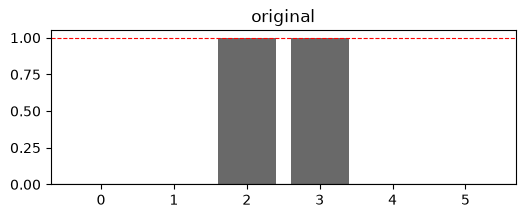

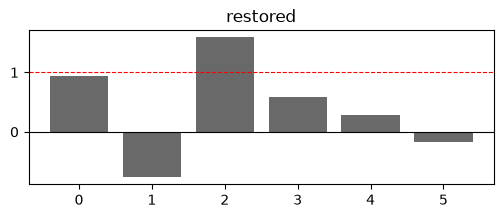

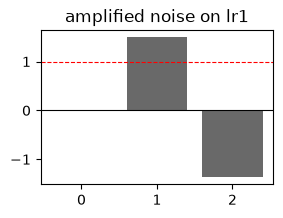

In [36]:
def noisy_1(shift_1, shift_2):
    rng = np.random.default_rng(SEED)  

    D = generate_2x_avg_D(len(HR_1D))
    M1 = generate_M(len(HR_1D), shift_1)
    M2 = generate_M(len(HR_1D), shift_2)

    lr1_noisy = generate_lr_image(HR_1D, D, shift_1) + rng.normal(0, NOISE_STD, 3)
    lr2_noisy = generate_lr_image(HR_1D, D, shift_2) + rng.normal(0, NOISE_STD, 3)

    A = np.vstack([D @ M1, D @ M2]) # as in Ax = y
    x = np.linalg.solve(A, np.concatenate([lr1_noisy, lr2_noisy]))

    return (lr1_noisy, lr2_noisy, x)

result_noisy = noisy_1(0.5, 0.75)

draw_1d(HR_1D, "original")
draw_1d(result_noisy[2], "restored")
draw_1d((result_noisy[0] - result_naive[0]) * 100, "amplified noise on lr1") # * 10, because otherwise it would be hard to see


So, because of noise, system could not be solved exactly. This happens because chosen shifts are too close together (`0,5` and `0,75`) and model could not tell them apart from the noise. 

To counter this we can try to:
1. Add more images
2. Use better separated shifts

Mathematically, low delta between shifts lead to final system being ill-conditioned

## Understanding shift separations

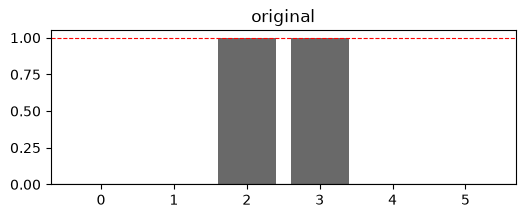

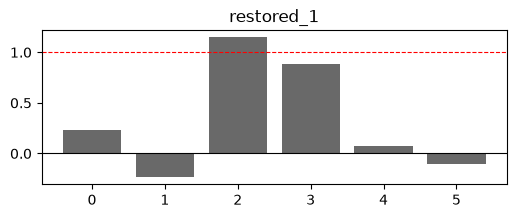

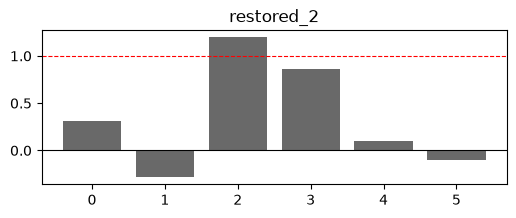

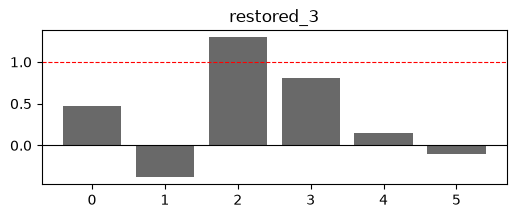

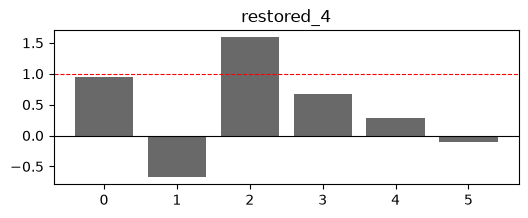

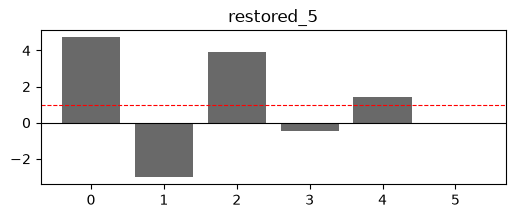

In [37]:
# Lets try better shift separation:
draw_1d(HR_1D, "original")

shift_sep_result_1 = noisy_1(0, 1)
shift_sep_result_2 = noisy_1(0.25, 1)
shift_sep_result_3 = noisy_1(0.5, 1)
shift_sep_result_4 = noisy_1(0.75, 1)
shift_sep_result_5 = noisy_1(0.95, 1)

draw_1d(shift_sep_result_1[2], "restored_1") # Shows the best recovery result
draw_1d(shift_sep_result_2[2], "restored_2")
draw_1d(shift_sep_result_3[2], "restored_3")
draw_1d(shift_sep_result_4[2], "restored_4")
draw_1d(shift_sep_result_5[2], "restored_5")


So, the less different images are, the harder it is to distinguish noise from signal and recover original image.

[Park et al, 2003](https://perso.telecom-paristech.fr/maitre/cours/projet_superresolution/park.pdf): describes an extreme case – when images are shifted by integer LR pixels, the images would carry identical information: 

> If the LR images are shifted by integer units, then
each image contains the same information, and thus there
is no new information that can be used to reconstruct an
HR image. If the LR images have different subpixel shifts
from each other and if aliasing is present, however, then
each image cannot be obtained from the others. In this
case, the new information contained in each LR image
can be exploited to obtain an HR image.

Note: In this notebook we use subpixel shifts relevant of HR image. So when we say shift by 1px we mean: 
- shift by 1 HR pixel 
- shift by 0.5 LR pixels  

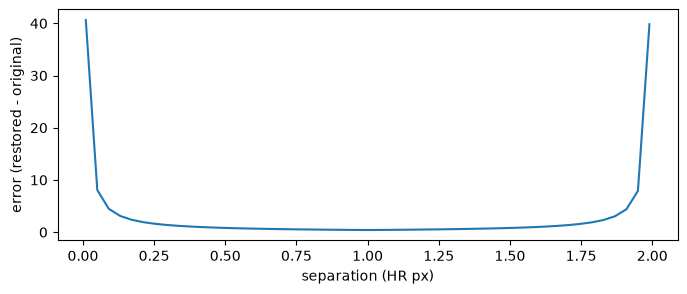

In [38]:
separations = np.linspace(MIN_SHIFT, MAX_SHIFT, 50)
 
errors = []
for e in separations:
    result = noisy_1(0, e)
    restored = result[2]
    error = np.linalg.norm(restored - HR_1D)
    errors.append(error)

plt.figure(figsize=(8, 3))
plt.plot(separations, errors)
plt.xlabel("separation (HR px)")
plt.ylabel("error (restored - original)")
plt.show()

Empirically, recovery error is minimized at shift separation near 0.5 LR px shift (1px HR shift) and diverges as separation approaches 0 or 1 LR px.

## Adding more images

Lets build a generic function and try adding more images and seeing how it affects the reconstruction

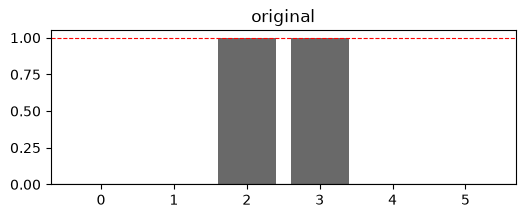

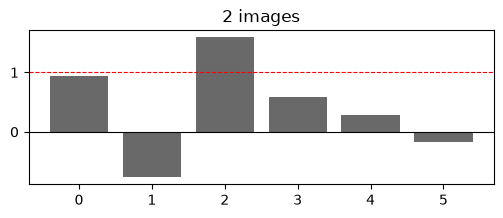

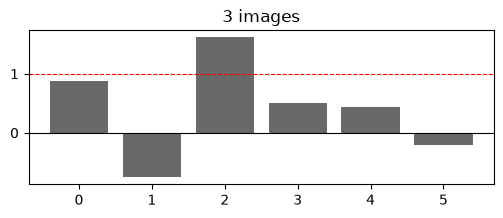

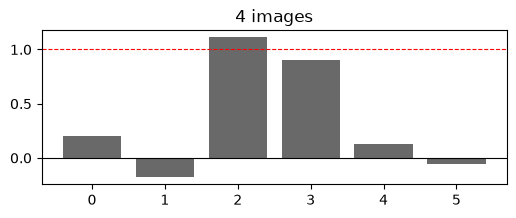

In [39]:
def noisy_generic(shifts):
    rng = np.random.default_rng(SEED)

    D = generate_2x_avg_D(len(HR_1D))

    M = [generate_M(len(HR_1D), s) for s in shifts]

    LR = [generate_lr_image(HR_1D, D, s) + rng.normal(0, NOISE_STD, 3) for s in shifts]
   
    A = np.vstack([D @ m for m in M])
    x = np.linalg.lstsq(A, np.concatenate(LR), rcond=None)[0]
    
    return (LR, x)

res2 = noisy_generic([0.5, 0.75])
res3 = noisy_generic([0.5, 0.75, 1.5])
res4 = noisy_generic([0.5, 0.75, 1.5, 1.0])

draw_1d(HR_1D, "original")
draw_1d(res2[1], "2 images")
draw_1d(res3[1], "3 images")
draw_1d(res4[1], "4 images")


Empirically, adding photos with distinct subpixel shifts helps, while adding photos with same shift does not help.

## In conclusion:

1. Adding noise makes the original HR image not recoverable.
2. We can reconstruct an image that is `close` to the original HR if selected group of LR images is large enough and has enough distinction in shifts.

# 1D MSSR with Noise and Blur

In this scenario, blur operator would do the same as D operator (because we are downsampling by averaging adjacent pixles)

Expectation here is – Blur would just make recovery harder 

In [40]:
def generate_B(n):
    B = np.zeros((n, n))
    for i in range(n):
        B[i, i] = 0.5
        if i > 0: 
            B[i, i-1] = 0.25
        if i < n-1:
            B[i, i+1] = 0.25
    return B

def blur_only(shifts):
    D = generate_2x_avg_D(len(HR_1D))
    B = generate_B(len(HR_1D))
    M = [generate_M(len(HR_1D), s) for s in shifts]
    LR = [D @ B @ m @ HR_1D for m in M]
    A = np.vstack([D @ B @ m for m in M])
    x = np.linalg.lstsq(A, np.concatenate(LR), rcond=None)[0]
    return (LR, x)
 
def blur_and_noise(shifts):
    rng = np.random.default_rng(SEED)
    D = generate_2x_avg_D(len(HR_1D))
    B = generate_B(len(HR_1D))
    M = [generate_M(len(HR_1D), s) for s in shifts]
    LR = [D @ B @ m @ HR_1D + rng.normal(0, NOISE_STD, 3) for m in M]
    A = np.vstack([D @ B @ m for m in M])
    x = np.linalg.lstsq(A, np.concatenate(LR), rcond=None)[0]
    return (LR, x)
 
for shifts in [[0, 1], [0.5, 0.75, 1.5], [0, 0.25, 0.5, 0.75, 1.5, 1.0]]:
    e_blur  = np.linalg.norm(blur_only(shifts)[1]  - HR_1D)
    e_noise = np.linalg.norm(noisy_generic(shifts)[1] - HR_1D)
    e_both  = np.linalg.norm(blur_and_noise(shifts)[1] - HR_1D)
    print(f"{len(shifts)} imgs | noise: {e_noise:.3f} | blur: {e_blur:.3f} | blur+noise: {e_both:.3f}")

2 imgs | noise: 0.402 | blur: 0.000 | blur+noise: 1.673
3 imgs | noise: 1.486 | blur: 0.000 | blur+noise: 2.010
6 imgs | noise: 0.080 | blur: 0.000 | blur+noise: 0.236


# Registration problem

In real world we can't control our shifts so M matrix needs to be approximated. One way of doing this is by using residual sweeping

In [ ]:
def get_shift_by_residuals():
    true_shift = 0.75
    lr1, lr2 = blur_and_noise([0, true_shift])[0]
    
    D = generate_2x_avg_D(len(HR_1D))
    B = generate_B(len(HR_1D))

    candidates = np.linspace(MIN_SHIFT, MAX_SHIFT, 100)
    residuals = []
    for s in candidates:
        A = np.vstack([D @ B @ generate_M(len(HR_1D), 0), D @ B @ generate_M(len(HR_1D), s)])
        x = np.linalg.lstsq(A, np.concatenate([lr1, lr2]), rcond=None)[0]
        residuals.append(np.linalg.norm(A @ x - np.concatenate([lr1, lr2])))

    best = candidates[np.argmin(residuals)]
    print("estimated shift: " + str(best) + " (true: " + str(true_shift) + ")")

get_shift_by_residuals()

estimated shift: 0.8300000000000001 (true: 0.75)
